# 02 · Exploratory data analysis

**Holdout discipline.**
* `dev` = 2016–2024 is used only for *descriptive* views (totals, seasonal curves, drift).
* `ana` = 2016–2021 (the first fold's training years) is used for every *relationship* analysis
  that could steer feature design: lag correlations, adjusted models, interaction tests, transitions.
* 2025, the locked test year, is not loaded into any analysis here.

**Association is not causation.** All lag relationships below are associations in a synthetic dataset.
Unadjusted correlations are confounded by the shared seasonal cycle, so each one is paired with an
adjusted view: seasonal anomalies, within-season subsets, or a multivariable Poisson model with month effects.

Figures go to `reports/eda/figures/`, tables to `reports/eda/tables/`, and headline numbers to
`reports/eda/eda_summary.json`. The written findings are in `reports/eda/README.md`.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
np.random.seed(2026)
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.tsa.stattools import acf, pacf
from scipy.stats import chi2
from dengueshield.data import load_panel

FIG = ROOT / "reports/eda/figures"; TAB = ROOT / "reports/eda/tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
S = {}  # headline numbers

# Validated reference palette (dataviz skill): fixed categorical order, one-hue sequential, blue<->red diverging.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, SURF, MUTED = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb", "#b9b8b2"
SEQ = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "lines.linewidth": 2, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "axes.prop_cycle": cycler(color=SERIES),
    "figure.dpi": 100, "savefig.dpi": 130, "savefig.bbox": "tight"})
CITIES = ["Dhaka North", "Dhaka South", "Chattogram", "Gazipur", "Narayanganj"]
CITY_COLOR = dict(zip(CITIES, SERIES))
def save(fig, name):
    fig.savefig(FIG / f"{name}.png"); plt.show(); plt.close(fig)

panel = load_panel()
panel["year"], panel["month"] = panel.date.dt.year, panel.date.dt.month
panel["woy"] = panel.date.dt.isocalendar().week.astype(int).clip(upper=52)
panel["dens_10k"] = panel.population_density_sqkm / 1e4
dev = panel[panel.year <= 2024].reset_index(drop=True)
ana = panel[panel.year <= 2021].reset_index(drop=True)
assert dev.year.max() == 2024 and ana.year.max() == 2021
print(len(dev), len(ana))

28200 18780


## 1. Cases by year, month, city and ward (descriptive, 2016–2024)

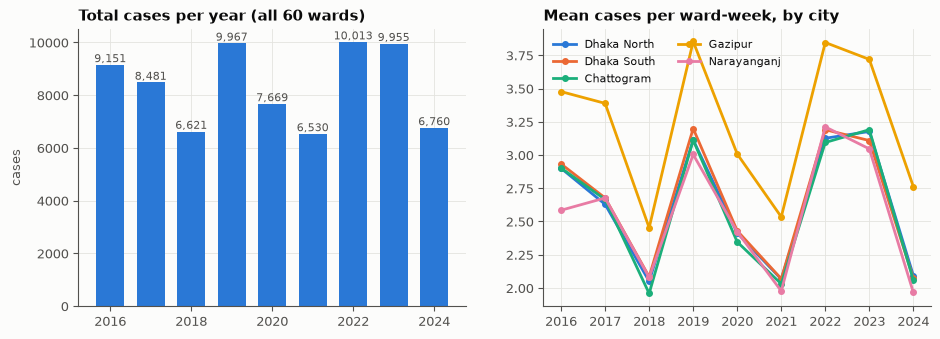

In [2]:
yc = dev.groupby(["year", "city"]).dengue_cases.agg(total="sum", per_ward_week="mean").reset_index()
yc.to_csv(TAB / "cases_by_year_city.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
tot = dev.groupby("year").dengue_cases.sum()
ax[0].bar(tot.index, tot.values, color=SERIES[0], width=0.7)
ax[0].set_title("Total cases per year (all 60 wards)"); ax[0].set_ylabel("cases")
for y, v in tot.items(): ax[0].text(y, v, f"{v:,}", ha="center", va="bottom", fontsize=8, color=INK2)
for c in CITIES:
    s = yc[yc.city == c]; ax[1].plot(s.year, s.per_ward_week, color=CITY_COLOR[c], marker="o", ms=4, label=c)
ax[1].set_title("Mean cases per ward-week, by city"); ax[1].legend(ncol=2, fontsize=8)
save(fig, "01_cases_by_year_city")
S["annual_totals_2016_2024"] = tot.to_dict()

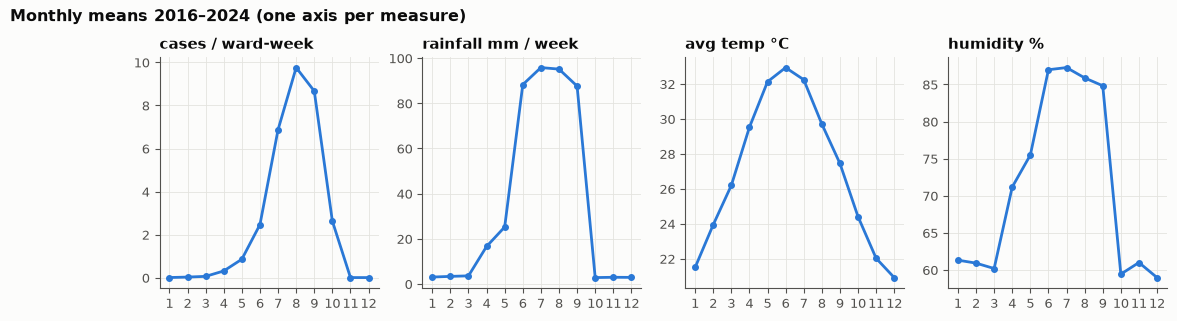

,dengue_cases,rainfall_mm,avg_temp_c,relative_humidity_pct
month,,,,
1,0.01,3.06,21.50,61.32
2,0.03,3.36,23.94,60.92
3,0.06,3.60,26.19,60.19
4,0.31,16.62,29.52,71.18
5,0.86,25.23,32.13,75.49
6,2.47,88.27,32.94,86.99
7,6.87,95.82,32.25,87.28
8,9.76,95.14,29.71,85.89
9,8.67,87.63,27.45,84.83


In [3]:
m = dev.groupby("month")[["dengue_cases", "rainfall_mm", "avg_temp_c", "relative_humidity_pct"]].mean()
m.round(3).to_csv(TAB / "monthly_profile.csv")
fig, ax = plt.subplots(1, 4, figsize=(13, 3))
for a, (col, lab) in zip(ax, [("dengue_cases", "cases / ward-week"), ("rainfall_mm", "rainfall mm / week"),
                              ("avg_temp_c", "avg temp °C"), ("relative_humidity_pct", "humidity %")]):
    a.plot(m.index, m[col], color=SERIES[0], marker="o", ms=4); a.set_title(lab); a.set_xticks(range(1, 13))
fig.suptitle("Monthly means 2016–2024 (one axis per measure)", x=0.01, y=1.04, ha="left", fontweight="bold")
save(fig, "02_monthly_profiles")
m.round(2)

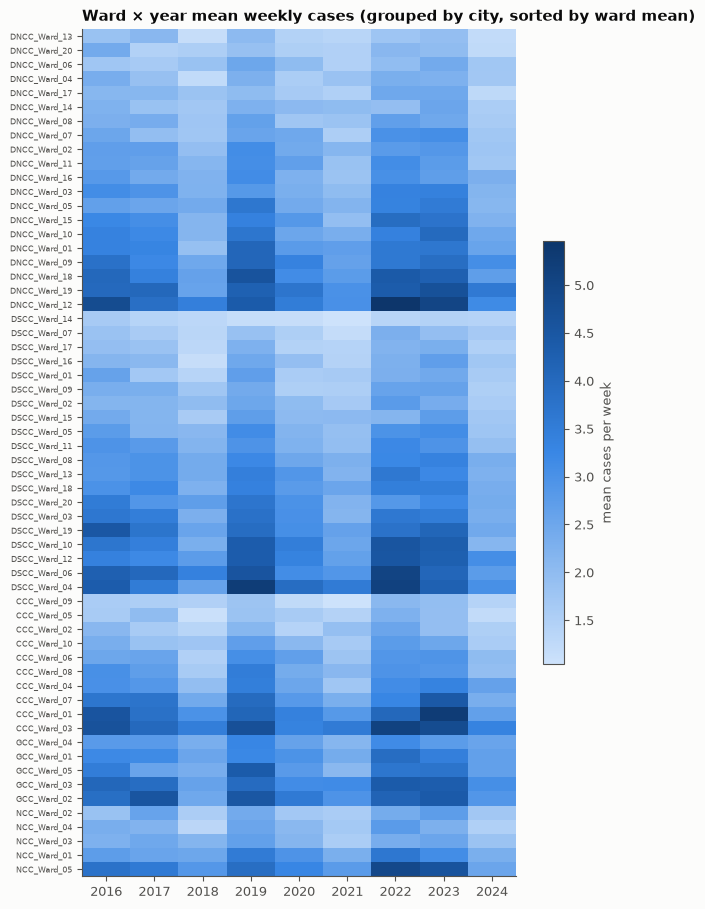

In [4]:
wy = dev.pivot_table(index="ward_id", columns="year", values="dengue_cases", aggfunc="mean")
order = dev.groupby("ward_id").agg(city=("city", "first"), m=("dengue_cases", "mean"))
order["c"] = order.city.map({c: i for i, c in enumerate(CITIES)})
wy = wy.loc[order.sort_values(["c", "m"]).index]
wy.round(3).to_csv(TAB / "ward_year_mean_cases.csv")
fig, ax = plt.subplots(figsize=(7, 11))
im = ax.imshow(wy.values, aspect="auto", cmap=SEQ)
ax.set_yticks(range(len(wy))); ax.set_yticklabels(wy.index, fontsize=6); ax.set_xticks(range(wy.shape[1])); ax.set_xticklabels(wy.columns)
ax.grid(False); fig.colorbar(im, ax=ax, label="mean cases per week", shrink=0.5)
ax.set_title("Ward × year mean weekly cases (grouped by city, sorted by ward mean)")
save(fig, "03_ward_year_heatmap")
S["ward_mean_cases_range_dev"] = [round(float(order.m.min()), 3), round(float(order.m.max()), 3)]

## 2. Weekly seasonal outbreak pattern

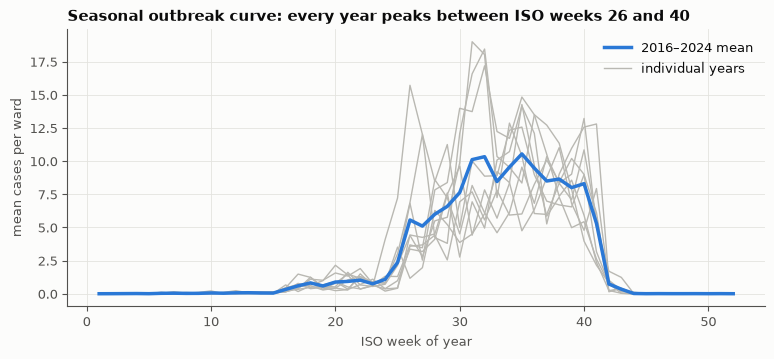

city,Dhaka North,Dhaka South,Chattogram,Gazipur,Narayanganj
year,,,,,
2016,31,31,32,31,31
2017,35,35,35,41,41
2018,37,37,39,36,39
2019,32,32,32,30,32
2020,40,40,40,40,40
2021,38,38,38,34,38
2022,26,26,26,26,26
2023,32,32,32,32,32
2024,35,35,35,35,35


In [5]:
nat = dev.groupby("date")[["dengue_cases", "rainfall_mm", "avg_temp_c", "relative_humidity_pct"]].mean()
nat["year"], nat["woy"] = nat.index.year, nat.index.isocalendar().week.clip(upper=52).values
curves = nat.pivot_table(index="woy", columns="year", values="dengue_cases")
fig, ax = plt.subplots(figsize=(9, 3.6))
for y in curves: ax.plot(curves.index, curves[y], color=MUTED, lw=1)
ax.plot(curves.index, curves.mean(axis=1), color=SERIES[0], lw=2.5, label="2016–2024 mean")
ax.plot([], [], color=MUTED, lw=1, label="individual years")
ax.set_xlabel("ISO week of year"); ax.set_ylabel("mean cases per ward"); ax.legend()
ax.set_title("Seasonal outbreak curve: every year peaks between ISO weeks 26 and 40")
save(fig, "04_seasonal_curves")

city_w = dev.groupby(["city", "year", "date"]).dengue_cases.mean().reset_index()
city_w["woy"] = city_w.date.dt.isocalendar().week.clip(upper=52).values
pk = city_w.loc[city_w.groupby(["city", "year"]).dengue_cases.idxmax()][["city", "year", "woy", "dengue_cases"]]
pk = pk.rename(columns={"woy": "peak_week", "dengue_cases": "peak_mean_cases_per_ward"})
pk.to_csv(TAB / "peak_by_city_year.csv", index=False)
peak_w = pk.pivot(index="year", columns="city", values="peak_week")[CITIES]
S["national_peak_week_by_year"] = curves.idxmax().to_dict()
S["city_peak_week_range_within_year_max"] = int((peak_w.max(axis=1) - peak_w.min(axis=1)).max())
active = nat[nat.dengue_cases >= 1].groupby("year").woy.agg(["min", "max"])
S["active_season_weeks_mean_ge_1"] = active.to_dict("index")
peak_w

## 3. Rainfall and subsequent cases

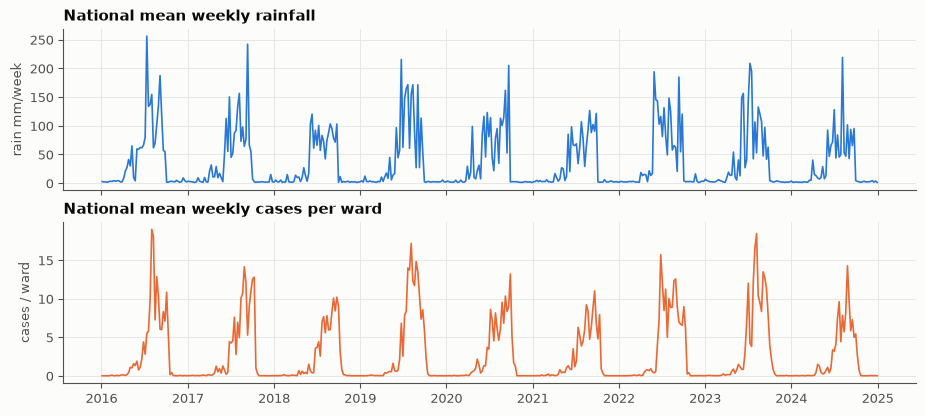

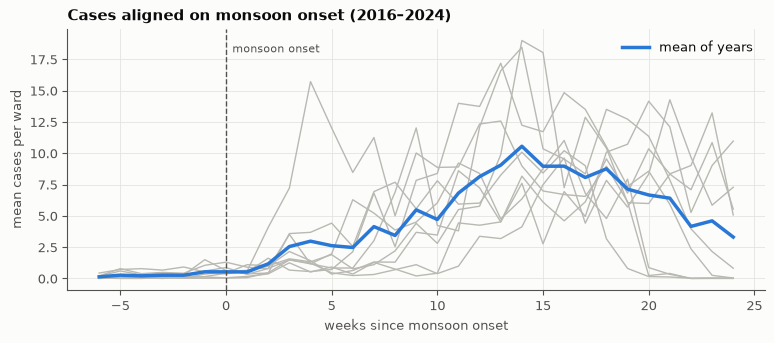

,year,onset,end,wet_weeks,season_rain_mm,weeks_onset_to_mean_ge_1,weeks_onset_to_peak,weeks_end_to_mean_lt_1
0,2016,2016-04-25,2016-09-26,21,2144.0,1,14,3
1,2017,2017-04-10,2017-09-25,18,1844.6,3,20,4
2,2018,2018-06-04,2018-09-24,17,1606.3,3,16,3
3,2019,2019-05-06,2019-09-23,16,2041.9,2,13,3
4,2020,2020-04-20,2020-09-21,18,1882.2,3,23,5
5,2021,2021-05-31,2021-09-27,16,1582.4,0,16,3
6,2022,2022-05-30,2022-09-26,17,2082.6,2,4,3
7,2023,2023-05-01,2023-09-25,18,1995.2,3,14,3
8,2024,2024-04-01,2024-09-23,18,1562.3,3,21,3


In [6]:
fig, ax = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True)
ax[0].plot(nat.index, nat.rainfall_mm, color=SERIES[0], lw=1.2); ax[0].set_ylabel("rain mm/week"); ax[0].set_title("National mean weekly rainfall")
ax[1].plot(nat.index, nat.dengue_cases, color=SERIES[1], lw=1.2); ax[1].set_ylabel("cases / ward"); ax[1].set_title("National mean weekly cases per ward")
save(fig, "05_rain_and_cases_timeseries")

# Monsoon onset event study: onset = first week the national mean rain exceeds 30 mm.
rows, aligned = [], {}
for y, g in nat.groupby("year"):
    wet = g[g.rainfall_mm > 30]
    onset, end = wet.index.min(), wet.index.max()
    first_case = g[(g.index >= onset) & (g.dengue_cases >= 1)].index.min()
    rows.append({"year": y, "onset": onset.date(), "end": end.date(), "wet_weeks": len(wet),
                 "season_rain_mm": round(g.rainfall_mm.sum(), 1), "weeks_onset_to_mean_ge_1": (first_case - onset).days // 7,
                 "weeks_onset_to_peak": (g.dengue_cases.idxmax() - onset).days // 7,
                 "weeks_end_to_mean_lt_1": (g[(g.index > end) & (g.dengue_cases < 1)].index.min() - end).days // 7})
    rel = ((g.index - onset).days // 7)
    aligned[y] = pd.Series(g.dengue_cases.values, index=rel)
season = pd.DataFrame(rows); season.to_csv(TAB / "monsoon_season_by_year.csv", index=False)
al = pd.DataFrame(aligned).loc[-6:24]
fig, ax = plt.subplots(figsize=(9, 3.4))
for y in al: ax.plot(al.index, al[y], color=MUTED, lw=1)
ax.plot(al.index, al.mean(axis=1), color=SERIES[0], lw=2.5, label="mean of years")
ax.axvline(0, color=INK2, lw=1, ls="--"); ax.text(0.3, al.max().max() * 0.95, "monsoon onset", color=INK2, fontsize=8)
ax.set_xlabel("weeks since monsoon onset"); ax.set_ylabel("mean cases per ward"); ax.legend()
ax.set_title("Cases aligned on monsoon onset (2016–2024)")
save(fig, "06_monsoon_onset_event_study")
S["monsoon"] = season.set_index("year")[["onset", "end", "weeks_onset_to_mean_ge_1", "weeks_onset_to_peak", "weeks_end_to_mean_lt_1"]].astype(str).to_dict("index")
season

## 4. Cross-correlations, lags 0–8 (analysis window 2016–2021)

Three views of corr(cases_t, X_{t−k}) per ward, pooled:
* **raw**: confounded by the shared seasonal cycle;
* **seasonal anomaly**: both series minus their ward × week-of-year mean, so it only measures
  whether *unusual* weather precedes *unusual* case counts;
* **in-season**: raw, restricted to target weeks in June–October.

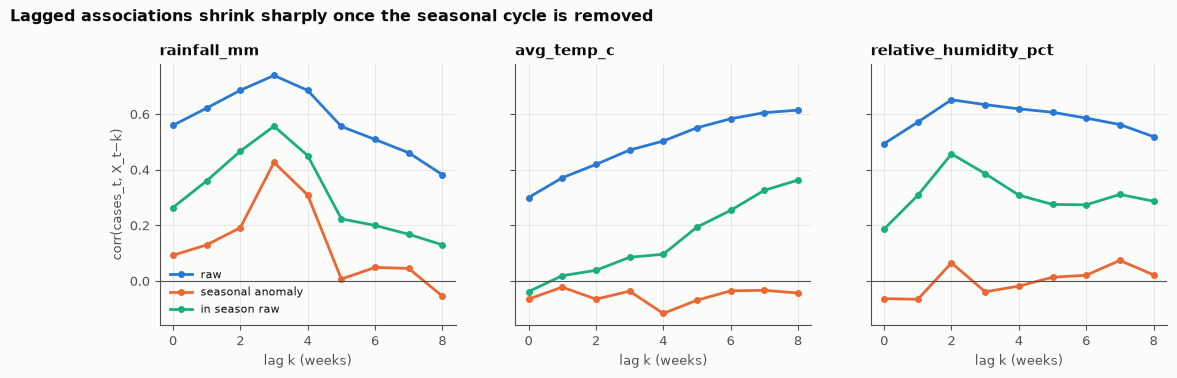

raw                                   seasonal_anomaly                                   in_season_raw                                  
variable avg_temp_c rainfall_mm relative_humidity_pct       avg_temp_c rainfall_mm relative_humidity_pct    avg_temp_c rainfall_mm relative_humidity_pct
lag                                                                                                                                                     
0             0.299       0.559                 0.493           -0.066       0.092                -0.064        -0.039       0.263                 0.186
1             0.370       0.621                 0.571           -0.023       0.129                -0.067         0.018       0.359                 0.307
2             0.418       0.685                 0.651           -0.066       0.191                 0.064         0.038       0.466                 0.456
3             0.470       0.738                 0.634           -0.037       0.426                -0.040         0.085       0.556                 0.385
4             0.503       0.685                 0.618           -0.118       0.308                -0.019         0.095       0.450                 0.308
5             0.550       0.555                 0.606           -0.070       0.006                 0.013         0.193       0.223                 0.275
6             0.583       0.508                 0.585           -0.036       0.048                 0.020         0.253       0.199                 0.273
7             0.605       0.460                 0.562           -0.034       0.044                 0.073         0.325       0.167                 0.311
8             0.614       0.382                 0.518           -0.044      -0.055                 0.021         0.362       0.129                 0.286

In [7]:
def climatology_anomaly(df, col):
    return df[col] - df.groupby(["ward_id", "woy"])[col].transform("mean")
for c in ["dengue_cases", "rainfall_mm", "avg_temp_c", "relative_humidity_pct"]:
    ana[c + "_anom"] = climatology_anomaly(ana, c)
g = ana.groupby("ward_id")
in_season = ana.month.between(6, 10)
LAGS = range(0, 9)
rows = []
for x in ["rainfall_mm", "avg_temp_c", "relative_humidity_pct"]:
    for k in LAGS:
        xr, xa = g[x].shift(k), g[x + "_anom"].shift(k)
        ok = xr.notna()
        rows.append({"variable": x, "lag": k,
                     "raw": np.corrcoef(ana.dengue_cases[ok], xr[ok])[0, 1],
                     "seasonal_anomaly": np.corrcoef(ana.dengue_cases_anom[ok], xa[ok])[0, 1],
                     "in_season_raw": np.corrcoef(ana.dengue_cases[ok & in_season], xr[ok & in_season])[0, 1]})
ccf = pd.DataFrame(rows); ccf.round(4).to_csv(TAB / "cross_correlation_lags_0_8.csv", index=False)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for a, (x, d) in zip(ax, ccf.groupby("variable", sort=False)):
    for col, colr in zip(["raw", "seasonal_anomaly", "in_season_raw"], SERIES):
        a.plot(d.lag, d[col], color=colr, marker="o", ms=4, label=col.replace("_", " "))
    a.axhline(0, color=INK2, lw=0.8); a.set_title(x); a.set_xlabel("lag k (weeks)")
ax[0].set_ylabel("corr(cases_t, X_t−k)"); ax[0].legend(fontsize=8)
fig.suptitle("Lagged associations shrink sharply once the seasonal cycle is removed", x=0.01, y=1.04, ha="left", fontweight="bold")
save(fig, "07_cross_correlation_lags")
piv = ccf.pivot(index="lag", columns="variable", values=["raw", "seasonal_anomaly", "in_season_raw"])
S["ccf_peak_lag"] = {f"{v}|{x}": int(piv[(v, x)].idxmax()) for v in ["raw", "seasonal_anomaly", "in_season_raw"] for x in ["rainfall_mm", "avg_temp_c", "relative_humidity_pct"]}
S["ccf_rain"] = ccf[ccf.variable == "rainfall_mm"].set_index("lag")[["raw", "seasonal_anomaly", "in_season_raw"]].round(3).to_dict("index")
piv.round(3)

### Adjusted model: which lags survive when estimated jointly?
Poisson GLM on 2016–2021 with month fixed effects, static ward attributes, and lags 0–8 of rainfall,
average temperature and humidity entered *together*. Coefficients are rate ratios per unit.
This is an exploratory adjustment, not a forecasting model, and it uses lags that a 3- or 4-week
forecast cannot observe.

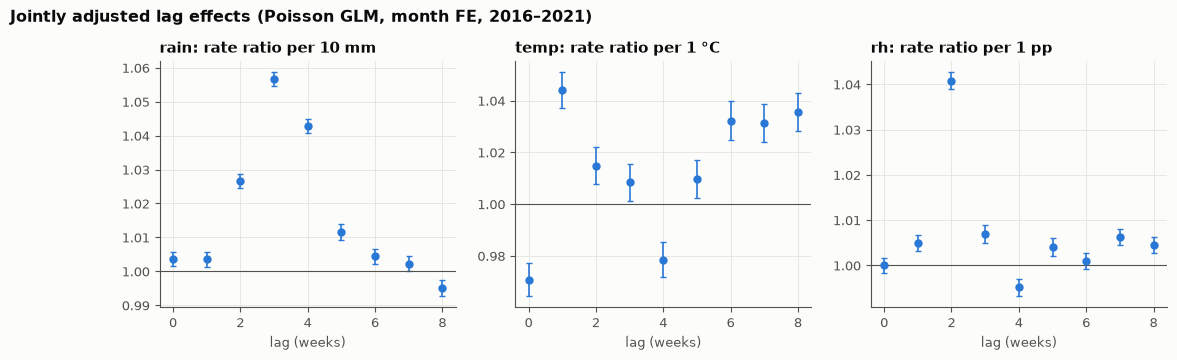

{'deviance_explained': np.float64(0.8567),
 'pearson_dispersion': np.float64(1.194),
 'rain_coef_by_lag': {0: 0.00037,
  1: 0.00035,
  2: 0.00263,
  3: 0.00551,
  4: 0.0042,
  5: 0.00116,
  6: 0.00045,
  7: 0.00023,
  8: -0.00049},
 'static_coefs': {'dens_10k': 0.0751,
  'water_logging_risk_index': 0.8795,
  'sanitation_score': -0.3541}}

In [8]:
for k in LAGS:
    ana[f"rain_l{k}"] = g.rainfall_mm.shift(k); ana[f"temp_l{k}"] = g.avg_temp_c.shift(k); ana[f"rh_l{k}"] = g.relative_humidity_pct.shift(k)
fit_df = ana.dropna(subset=[f"rain_l{k}" for k in LAGS])
terms = [f"{v}_l{k}" for v in ["rain", "temp", "rh"] for k in LAGS]
glm = smf.glm("dengue_cases ~ " + " + ".join(terms) + " + C(month) + dens_10k + water_logging_risk_index + sanitation_score",
              fit_df, family=sm.families.Poisson()).fit()
ci = glm.conf_int()
coef = pd.DataFrame({"coef": glm.params, "lo": ci[0], "hi": ci[1], "p": glm.pvalues}).loc[terms]
coef["variable"], coef["lag"] = coef.index.str.split("_l").str[0], coef.index.str.split("_l").str[1].astype(int)
coef.round(5).to_csv(TAB / "adjusted_glm_lag_coefficients.csv")
S["adjusted_glm"] = {"deviance_explained": round(1 - glm.deviance / glm.null_deviance, 4),
                     "pearson_dispersion": round(glm.pearson_chi2 / glm.df_resid, 3),
                     "rain_coef_by_lag": coef[coef.variable == "rain"].set_index("lag").coef.round(5).to_dict(),
                     "static_coefs": glm.params[["dens_10k", "water_logging_risk_index", "sanitation_score"]].round(4).to_dict()}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, (v, unit) in zip(ax, [("rain", "per 10 mm"), ("temp", "per 1 °C"), ("rh", "per 1 pp")]):
    d = coef[coef.variable == v]; sc = 10 if v == "rain" else 1
    a.errorbar(d.lag, np.exp(sc * d.coef), yerr=[np.exp(sc * d.coef) - np.exp(sc * d.lo), np.exp(sc * d.hi) - np.exp(sc * d.coef)],
               fmt="o", color=SERIES[0], ms=5, capsize=2, lw=1.2)
    a.axhline(1, color=INK2, lw=0.8); a.set_title(f"{v}: rate ratio {unit}"); a.set_xlabel("lag (weeks)")
fig.suptitle("Jointly adjusted lag effects (Poisson GLM, month FE, 2016–2021)", x=0.01, y=1.04, ha="left", fontweight="bold")
save(fig, "08_adjusted_lag_effects")
S["adjusted_glm"]

## 5. Temperature and humidity dependence (lag 3, chosen a priori as the centre of the brief's 2–4 week window)

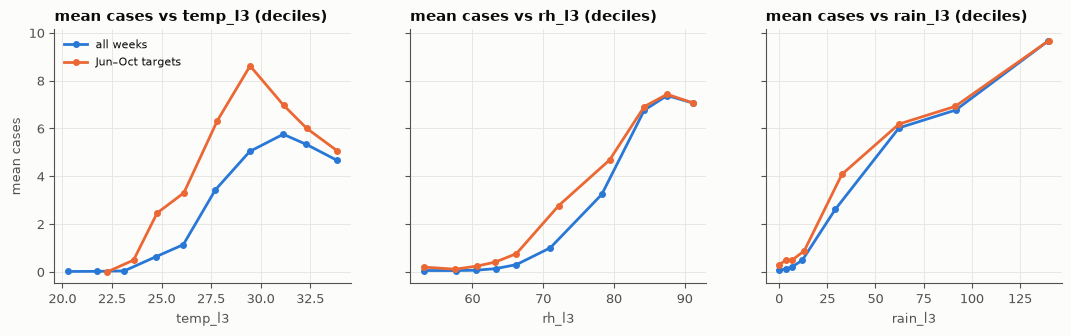

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
out = []
for a, x in zip(ax, ["temp_l3", "rh_l3", "rain_l3"]):
    d = ana.dropna(subset=[x]).copy(); d["bin"] = pd.qcut(d[x], 10, duplicates="drop")
    for lab, sub, col in [("all weeks", d, SERIES[0]), ("Jun–Oct targets", d[d.month.between(6, 10)], SERIES[1])]:
        b = sub.groupby("bin", observed=True).agg(x=(x, "median"), y=("dengue_cases", "mean"), n=("dengue_cases", "size"))
        a.plot(b.x, b.y, marker="o", ms=4, color=col, label=lab); out.append(b.assign(variable=x, subset=lab))
    a.set_title(f"mean cases vs {x} (deciles)"); a.set_xlabel(x)
ax[0].set_ylabel("mean cases"); ax[0].legend(fontsize=8)
save(fig, "09_weather_dependence_deciles")
pd.concat(out).reset_index().drop(columns="bin").round(3).to_csv(TAB / "weather_dependence_deciles.csv", index=False)

## 6. Ward vulnerability: waterlogging, sanitation, density, and their interactions

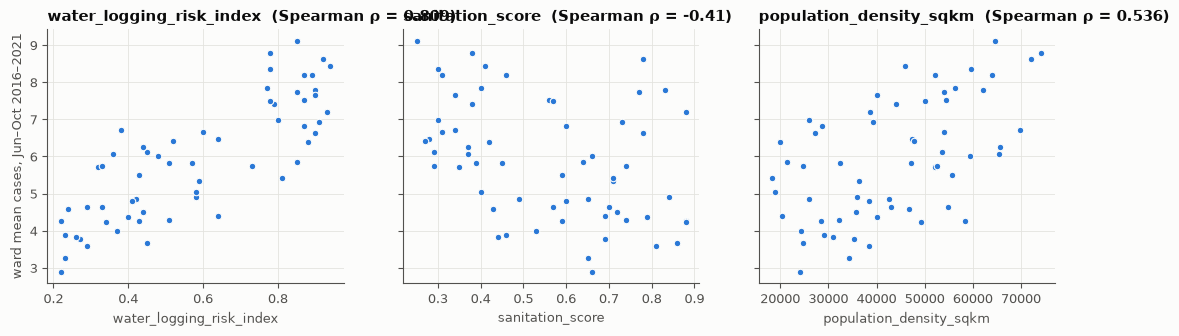

mean  size
wl_hi san_hi             
False False   5.331    14
      True    4.311    16
True  False   7.435    17
      True    6.416    13

,interaction,coef,LR_stat,p_value
0,rain_l3:water_logging_risk_index,0.0004,1.1520,0.2831
1,rain_l3:sanitation_score,0.0003,0.4461,0.5042
2,rain_l3:dens_10k,-0.0000,0.4637,0.4959
3,water_logging_risk_index:sanitation_score,0.4460,19.6245,0.0000
4,water_logging_risk_index:dens_10k,-0.0684,25.0545,0.0000
5,rh_l2:water_logging_risk_index,0.0058,3.9044,0.0482


In [10]:
peak = ana[ana.month.between(6, 10)]
ward = peak.groupby("ward_id").agg(city=("city", "first"), cases=("dengue_cases", "mean"),
                                   dens=("population_density_sqkm", "first"), wl=("water_logging_risk_index", "first"),
                                   san=("sanitation_score", "first"))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
rho = {}
for a, (c, lab) in zip(ax, [("wl", "water_logging_risk_index"), ("san", "sanitation_score"), ("dens", "population_density_sqkm")]):
    rho[lab] = round(ward[[c, "cases"]].corr(method="spearman").iloc[0, 1], 3)
    a.scatter(ward[c], ward.cases, s=22, color=SERIES[0], edgecolor=SURF, linewidth=0.8)
    a.set_title(f"{lab}  (Spearman ρ = {rho[lab]})"); a.set_xlabel(lab)
ax[0].set_ylabel("ward mean cases, Jun–Oct 2016–2021")
save(fig, "10_static_vulnerability")
S["static_spearman_with_peak_season_cases"] = rho
X = sm.add_constant(ward[["wl", "san"]].assign(dens=ward.dens / 1e4))
ols = sm.OLS(np.log(ward.cases), X).fit()
S["ward_level_log_cases_R2_from_statics"] = round(ols.rsquared, 3)

ward["wl_hi"], ward["san_hi"] = ward.wl > ward.wl.median(), ward.san > ward.san.median()
grid = ward.groupby(["wl_hi", "san_hi"]).cases.agg(["mean", "size"]).round(3)
grid.to_csv(TAB / "waterlogging_x_sanitation_peak_cases.csv")
display(grid)

# Likelihood-ratio tests of interactions on top of an additive model
base = ("dengue_cases ~ rain_l2 + rain_l3 + rain_l4 + rain_l5 + rh_l1 + rh_l2 + rh_l3 + temp_l6 + temp_l7 + temp_l8"
        " + C(month) + dens_10k + water_logging_risk_index + sanitation_score")
m0 = smf.glm(base, fit_df, family=sm.families.Poisson()).fit()
rows = []
for term in ["rain_l3:water_logging_risk_index", "rain_l3:sanitation_score", "rain_l3:dens_10k",
             "water_logging_risk_index:sanitation_score", "water_logging_risk_index:dens_10k", "rh_l2:water_logging_risk_index"]:
    m1 = smf.glm(base + " + " + term, fit_df, family=sm.families.Poisson()).fit()
    lr = 2 * (m1.llf - m0.llf)
    rows.append({"interaction": term, "coef": m1.params[term], "LR_stat": lr, "p_value": float(chi2.sf(lr, 1))})
inter = pd.DataFrame(rows); inter.round(5).to_csv(TAB / "interaction_lr_tests.csv", index=False)
S["interaction_lr_tests"] = inter.set_index("interaction")[["LR_stat", "p_value"]].round(4).to_dict("index")
inter.round(4)

## 7. Autocorrelation and partial autocorrelation

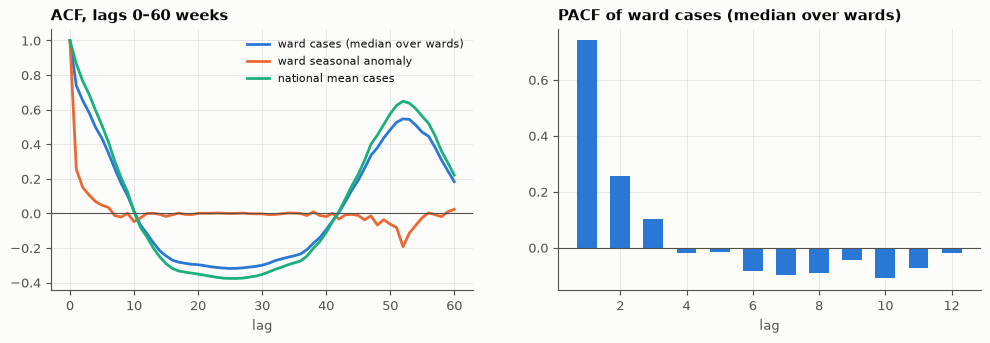

{'ward_lag': {1: 0.738, 2: 0.652, 3: 0.582, 4: 0.497, 52: 0.546},
 'ward_anomaly_lag': {1: 0.254, 2: 0.15, 3: 0.106, 4: 0.068, 52: -0.193},
 'ward_pacf_lag': {1: 0.741, 2: 0.257, 3: 0.103, 4: -0.018}}

In [11]:
nat_ana = ana.groupby("date")[["dengue_cases", "dengue_cases_anom"]].mean()
acf_nat = acf(nat_ana.dengue_cases, nlags=60)
acf_nat_anom = acf(nat_ana.dengue_cases_anom, nlags=60)
ward_acf = np.median([acf(s.values, nlags=60) for _, s in ana.groupby("ward_id").dengue_cases], axis=0)
ward_acf_anom = np.median([acf(s.values, nlags=60) for _, s in ana.groupby("ward_id").dengue_cases_anom], axis=0)
ward_pacf = np.median([pacf(s.values, nlags=12) for _, s in ana.groupby("ward_id").dengue_cases], axis=0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
L = np.arange(61)
ax[0].plot(L, ward_acf, color=SERIES[0], label="ward cases (median over wards)")
ax[0].plot(L, ward_acf_anom, color=SERIES[1], label="ward seasonal anomaly")
ax[0].plot(L, acf_nat, color=SERIES[2], label="national mean cases")
ax[0].axhline(0, color=INK2, lw=0.8); ax[0].set_title("ACF, lags 0–60 weeks"); ax[0].legend(fontsize=8); ax[0].set_xlabel("lag")
ax[1].bar(np.arange(1, 13), ward_pacf[1:], color=SERIES[0], width=0.6)
ax[1].axhline(0, color=INK2, lw=0.8); ax[1].set_title("PACF of ward cases (median over wards)"); ax[1].set_xlabel("lag")
save(fig, "11_acf_pacf")
acf_tab = pd.DataFrame({"lag": L, "ward_acf": ward_acf, "ward_anom_acf": ward_acf_anom, "national_acf": acf_nat})
acf_tab.round(4).to_csv(TAB / "acf.csv", index=False)
S["acf"] = {"ward_lag": {k: round(float(ward_acf[k]), 3) for k in [1, 2, 3, 4, 52]},
            "ward_anomaly_lag": {k: round(float(ward_acf_anom[k]), 3) for k in [1, 2, 3, 4, 52]},
            "ward_pacf_lag": {k: round(float(ward_pacf[k]), 3) for k in [1, 2, 3, 4]}}
S["acf"]

## 8. Zero-to-outbreak transition dynamics
States are defined from the analysis-window distribution: 0, 1–4, 5 to just below the P90 threshold, and ≥ P90 ("outbreak").

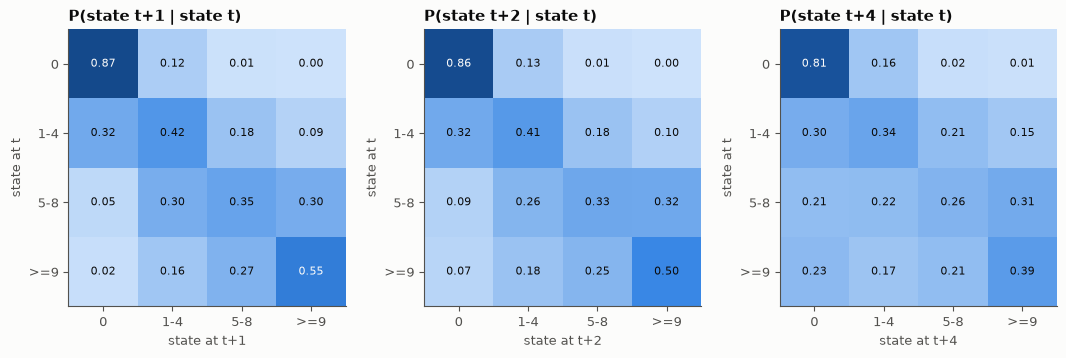

({'h1': {'P_outbreak_given_zero': 0.0013, 'P_outbreak_stays': 0.5524},
  'h2': {'P_outbreak_given_zero': 0.0034, 'P_outbreak_stays': 0.4971},
  'h4': {'P_outbreak_given_zero': 0.0086, 'P_outbreak_stays': 0.391}},
 {'2w_before': 0.0176, '3w_before': 0.0219, '4w_before': 0.0438})

In [12]:
q90 = float(ana.dengue_cases.quantile(0.9))
bins = [-0.5, 0.5, 4.5, q90 - 0.5, np.inf]; labels = ["0", "1-4", f"5-{int(q90) - 1}", f">={int(q90)}"]
ana["state"] = pd.cut(ana.dengue_cases, bins, labels=labels)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
S["outbreak_threshold_q90_2016_2021"] = q90; S["transitions"] = {}
for a, h in zip(ax, [1, 2, 4]):
    nxt = ana.groupby("ward_id").state.shift(-h)
    tm = pd.crosstab(ana.state, nxt, normalize="index")
    tm.round(4).to_csv(TAB / f"state_transition_h{h}.csv")
    a.imshow(tm.values, cmap=SEQ, vmin=0, vmax=1); a.grid(False)
    for i in range(tm.shape[0]):
        for j in range(tm.shape[1]):
            v = tm.values[i, j]; a.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color=SURF if v > 0.55 else INK)
    a.set_xticks(range(4)); a.set_xticklabels(tm.columns); a.set_yticks(range(4)); a.set_yticklabels(tm.index)
    a.set_xlabel(f"state at t+{h}"); a.set_ylabel("state at t"); a.set_title(f"P(state t+{h} | state t)")
    S["transitions"][f"h{h}"] = {"P_outbreak_given_zero": round(float(tm.loc["0"].iloc[-1]), 4),
                                 "P_outbreak_stays": round(float(tm.iloc[-1, -1]), 4)}
save(fig, "12_state_transitions")
# Outbreak weeks with zero cases 2 and 4 weeks earlier: the hardest early-warning cases
gg = ana.groupby("ward_id").dengue_cases
ob = ana.dengue_cases >= q90
S["outbreak_weeks_preceded_by_zero"] = {f"{h}w_before": round(float((gg.shift(h)[ob] == 0).mean()), 4) for h in [2, 3, 4]}
S["transitions"], S["outbreak_weeks_preceded_by_zero"]

## 9. Geographic heterogeneity

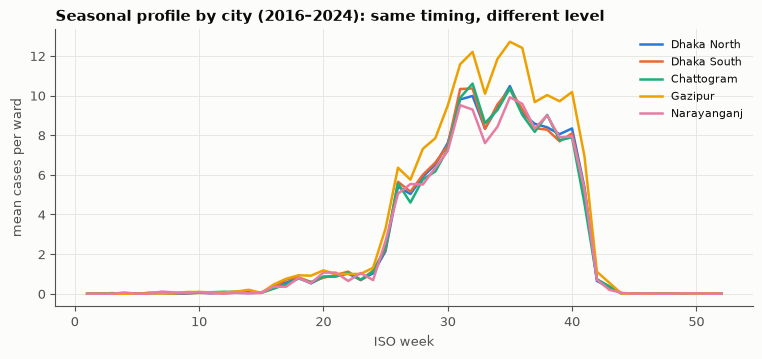

{'rainfall_mm': 0.0696, 'relative_humidity_pct': 0.0085, 'avg_temp_c': 0.014}

In [13]:
cw = dev.groupby(["city", "woy"]).dengue_cases.mean().unstack(0)[CITIES]
fig, ax = plt.subplots(figsize=(9, 3.6))
for c in CITIES:
    ax.plot(cw.index, cw[c], color=CITY_COLOR[c], label=c, lw=1.8)
ax.legend(fontsize=8); ax.set_xlabel("ISO week"); ax.set_ylabel("mean cases per ward")
ax.set_title("Seasonal profile by city (2016–2024): same timing, different level")
save(fig, "13_city_seasonal_profiles")
shape = cw.div(cw.sum())
S["city_profile_shape_corr_min"] = round(float(shape.corr().min().min()), 4)
S["city_peak_week_of_mean_profile"] = cw.idxmax().to_dict()

# Within a city and week, is a ward's own weather deviation associated with its case deviation 3 weeks later?
d = ana.copy()
for c in ["rainfall_mm", "relative_humidity_pct", "avg_temp_c"]:
    d[c + "_dev"] = d[c] - d.groupby(["city", "date"])[c].transform("mean")
d["case_ratio_dev"] = np.log1p(d.dengue_cases) - d.groupby(["city", "date"]).dengue_cases.transform(lambda s: np.log1p(s).mean())
gd = d.groupby("ward_id")
S["ward_weather_deviation_corr_lag3"] = {c: round(float(d.case_ratio_dev.corr(gd[c + "_dev"].shift(3))), 4)
                                         for c in ["rainfall_mm", "relative_humidity_pct", "avg_temp_c"]}
S["ward_weather_deviation_corr_lag3"]

## 10. Extreme-weather windows (seasonal anomalies, top 5% of ward-weeks)

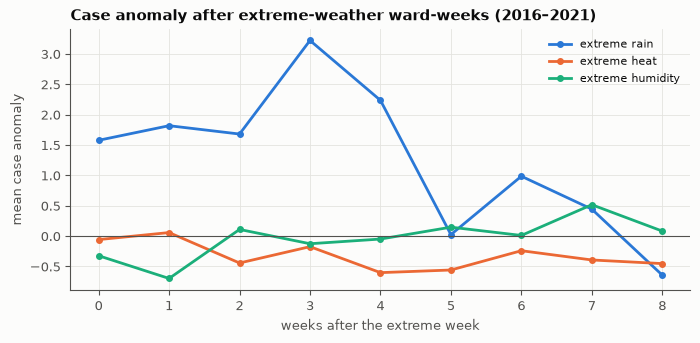

{'counts': {'extreme rain': {'ward_weeks': 939, 'distinct_dates': 24},
  'extreme heat': {'ward_weeks': 939, 'distinct_dates': 67},
  'extreme humidity': {'ward_weeks': 939, 'distinct_dates': 91}},
 'peak_response': {'extreme rain': [3, 3.221],
  'extreme heat': [1, 0.057],
  'extreme humidity': [7, 0.516]}}

In [14]:
resp, counts = {}, {}
for x, lab in [("rainfall_mm_anom", "extreme rain"), ("avg_temp_c_anom", "extreme heat"), ("relative_humidity_pct_anom", "extreme humidity")]:
    thr = ana[x].quantile(0.95); ev = ana[x] >= thr
    counts[lab] = {"ward_weeks": int(ev.sum()), "distinct_dates": int(ana.loc[ev, "date"].nunique())}
    resp[lab] = {k: float(g.dengue_cases_anom.shift(-k)[ev].mean()) for k in range(0, 9)}
resp = pd.DataFrame(resp); resp.index.name = "weeks_after"
resp.round(4).to_csv(TAB / "extreme_weather_response.csv")
fig, ax = plt.subplots(figsize=(8, 3.4))
for c, col in zip(resp, SERIES): ax.plot(resp.index, resp[c], marker="o", ms=4, color=col, label=c)
ax.axhline(0, color=INK2, lw=0.8); ax.set_xlabel("weeks after the extreme week"); ax.set_ylabel("mean case anomaly")
ax.set_title("Case anomaly after extreme-weather ward-weeks (2016–2021)"); ax.legend(fontsize=8)
save(fig, "14_extreme_weather_response")
S["extreme_weather"] = {"counts": counts, "peak_response": {c: [int(resp[c].idxmax()), round(float(resp[c].max()), 3)] for c in resp}}
S["extreme_weather"]

## 11. Outbreak severity across years (descriptive, 2016–2024; n = 9 years, so treat r cautiously)

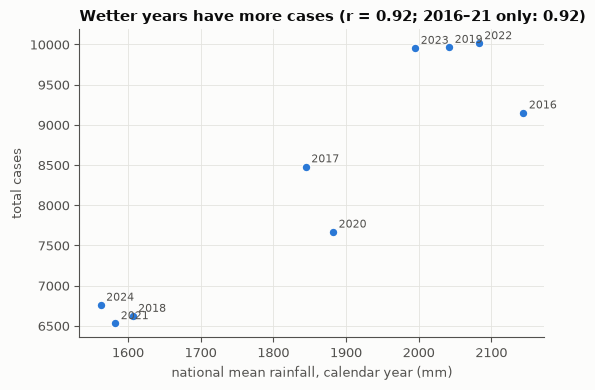

,season_rain_mm,wet_weeks,total_cases,peak_mean_cases
year,,,,
2016,2144.0,21,9151,19.000000
2017,1844.6,18,8481,14.150000
2018,1606.3,17,6621,10.200000
2019,2041.9,16,9967,17.183333
2020,1882.2,18,7669,13.216667
2021,1582.4,16,6530,11.016667
2022,2082.6,17,10013,15.716667
2023,1995.2,18,9955,18.450000
2024,1562.3,18,6760,14.266667


In [15]:
sev = season.set_index("year")[["season_rain_mm", "wet_weeks"]].join(dev.groupby("year").dengue_cases.sum().rename("total_cases"))
sev["peak_mean_cases"] = curves.max()
sev.to_csv(TAB / "severity_by_year.csv")
r_all = sev[["season_rain_mm", "total_cases"]].corr().iloc[0, 1]
r_ana = sev.loc[:2021, ["season_rain_mm", "total_cases"]].corr().iloc[0, 1]
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(sev.season_rain_mm, sev.total_cases, s=40, color=SERIES[0], edgecolor=SURF)
for y, r in sev.iterrows(): ax.annotate(str(y), (r.season_rain_mm, r.total_cases), xytext=(4, 3), textcoords="offset points", fontsize=8, color=INK2)
ax.set_xlabel("national mean rainfall, calendar year (mm)"); ax.set_ylabel("total cases")
ax.set_title(f"Wetter years have more cases (r = {r_all:.2f}; 2016–21 only: {r_ana:.2f})")
save(fig, "15_severity_vs_rain")
S["severity_rain_corr"] = {"2016_2024": round(float(r_all), 3), "2016_2021": round(float(r_ana), 3)}
sev

## 12. Reporting and systematic-artifact checks

In [16]:
art = {}
# Do cases move in lockstep across wards beyond weather? Correlation of ward anomaly series.
an = ana.pivot(index="date", columns="ward_id", values="dengue_cases_anom")
cmat = an.corr().values; city_of = ana.groupby("ward_id").city.first().reindex(an.columns).to_numpy(dtype=object)
same = city_of[:, None] == city_of[None, :]; off = ~np.eye(len(city_of), dtype=bool)
art["anomaly_corr_same_city_mean"] = round(float(cmat[same & off].mean()), 4)
art["anomaly_corr_diff_city_mean"] = round(float(cmat[~same].mean()), 4)
# Year-boundary discontinuity and 53-week years
wk = dev.groupby(dev.date.dt.isocalendar().week.values).dengue_cases.mean()
art["mean_cases_iso_week_52_53_1_2"] = {int(k): round(float(wk.get(k, np.nan)), 4) for k in [52, 53, 1, 2]}
# Integer heaping: share of even counts among positives (no reason to deviate from ~0.5)
pos = dev.dengue_cases[dev.dengue_cases > 0]
art["share_even_among_positive"] = round(float((pos % 2 == 0).mean()), 4)
art["share_multiples_of_5_among_counts_ge_5"] = round(float((pos[pos >= 5] % 5 == 0).mean()), 4)
# Off-season cases
art["share_cases_in_jan_mar_nov_dec"] = round(float(dev[dev.month.isin([1, 2, 3, 11, 12])].dengue_cases.sum() / dev.dengue_cases.sum()), 4)
S["artifacts"] = art
art

{'anomaly_corr_same_city_mean': 0.5189,
 'anomaly_corr_diff_city_mean': 0.5223,
 'mean_cases_iso_week_52_53_1_2': {52: 0.0037, 53: 0.0, 1: 0.0017, 2: 0.0056},
 'share_even_among_positive': 0.429,
 'share_multiples_of_5_among_counts_ge_5': 0.2577,
 'share_cases_in_jan_mar_nov_dec': 0.0035}

## 13. Nonstationarity: per-year distribution and in-season rain response

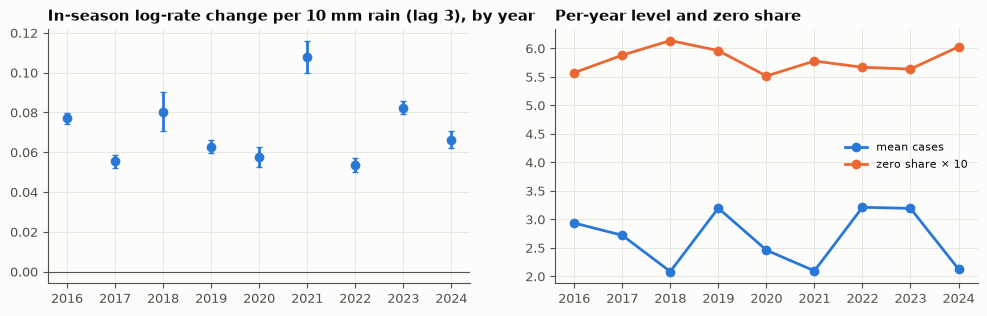

,rain_l3_coef,lo,hi,mean,zero_share,p90
year,,,,,,
2016,0.0077,0.0074,0.0080,2.9330,0.5571,10.0
2017,0.0055,0.0052,0.0059,2.7183,0.5878,10.0
2018,0.0080,0.0071,0.0090,2.0821,0.6135,8.0
2019,0.0063,0.0060,0.0066,3.1946,0.5958,12.0
2020,0.0058,0.0052,0.0063,2.4580,0.5513,8.0
2021,0.0108,0.0100,0.0116,2.0929,0.5776,7.0
2022,0.0054,0.0050,0.0057,3.2093,0.5667,11.0
2023,0.0082,0.0079,0.0086,3.1907,0.5635,12.0
2024,0.0066,0.0062,0.0070,2.1258,0.6025,8.0


In [17]:
dev2 = dev.copy(); gdv = dev2.groupby("ward_id")
dev2["rain_l3"], dev2["rh_l2"] = gdv.rainfall_mm.shift(3), gdv.relative_humidity_pct.shift(2)
rows = []
for y, d in dev2[dev2.month.between(6, 10)].dropna(subset=["rain_l3"]).groupby("year"):
    m = smf.glm("dengue_cases ~ rain_l3 + rh_l2 + dens_10k + water_logging_risk_index + sanitation_score", d, family=sm.families.Poisson()).fit()
    lo, hi = m.conf_int().loc["rain_l3"]
    yy = dev[dev.year == y].dengue_cases
    rows.append({"year": y, "rain_l3_coef": m.params["rain_l3"], "lo": lo, "hi": hi, "mean": yy.mean(),
                 "zero_share": (yy == 0).mean(), "p90": yy.quantile(0.9)})
ns = pd.DataFrame(rows).set_index("year"); ns.round(5).to_csv(TAB / "nonstationarity_by_year.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
ax[0].errorbar(ns.index, ns.rain_l3_coef * 10, yerr=[(ns.rain_l3_coef - ns.lo) * 10, (ns.hi - ns.rain_l3_coef) * 10], fmt="o", color=SERIES[0], capsize=2)
ax[0].set_title("In-season log-rate change per 10 mm rain (lag 3), by year"); ax[0].axhline(0, color=INK2, lw=0.8)
ax[1].plot(ns.index, ns["mean"], marker="o", color=SERIES[0], label="mean cases"); ax[1].plot(ns.index, ns.zero_share * 10, marker="o", color=SERIES[1], label="zero share × 10")
ax[1].set_title("Per-year level and zero share"); ax[1].legend(fontsize=8)
save(fig, "16_nonstationarity")
S["rain_l3_coef_by_year_x10"] = (ns.rain_l3_coef * 10).round(4).to_dict()
ns.round(4)

## 14. Weather predictability at the forecast origin (what a 3–4 week forecast cannot see)

In [18]:
nat_ana_w = ana.groupby("date")[["rainfall_mm", "rainfall_mm_anom", "relative_humidity_pct_anom", "avg_temp_c_anom"]].mean()
pred = {"rain_anomaly_acf": {k: round(float(nat_ana_w.rainfall_mm_anom.autocorr(k)), 3) for k in [1, 2, 3, 4]},
        "humidity_anomaly_acf": {k: round(float(nat_ana_w.relative_humidity_pct_anom.autocorr(k)), 3) for k in [1, 2, 3, 4]},
        "temp_anomaly_acf": {k: round(float(nat_ana_w.avg_temp_c_anom.autocorr(k)), 3) for k in [1, 2, 3, 4]}}
wet = nat_ana_w.rainfall_mm > 30
pred["P_wet_t_plus_2_given_wet_t"] = round(float(wet.shift(-2)[wet].mean()), 3)
pred["P_wet_t_plus_2_given_dry_t"] = round(float(wet.shift(-2)[~wet].mean()), 3)
clim = ana.groupby(["ward_id", "woy"]).rainfall_mm.transform("mean")
pred["rain_variance_explained_by_ward_week_climatology"] = round(float(1 - ((ana.rainfall_mm - clim) ** 2).sum() / ((ana.rainfall_mm - ana.rainfall_mm.mean()) ** 2).sum()), 3)
S["weather_predictability"] = pred
pred

{'rain_anomaly_acf': {1: 0.039, 2: -0.004, 3: 0.144, 4: -0.013},
 'humidity_anomaly_acf': {1: -0.031, 2: 0.011, 3: 0.029, 4: 0.05},
 'temp_anomaly_acf': {1: 0.009, 2: 0.15, 3: 0.016, 4: 0.052},
 'P_wet_t_plus_2_given_wet_t': 0.811,
 'P_wet_t_plus_2_given_dry_t': 0.098,
 'rain_variance_explained_by_ward_week_climatology': 0.732}

In [19]:
(ROOT / "reports/eda/eda_summary.json").write_text(json.dumps(S, indent=2, default=str))
print(json.dumps(S, indent=1, default=str)[:6000])

{
 "annual_totals_2016_2024": {
  "2016": 9151,
  "2017": 8481,
  "2018": 6621,
  "2019": 9967,
  "2020": 7669,
  "2021": 6530,
  "2022": 10013,
  "2023": 9955,
  "2024": 6760
 },
 "ward_mean_cases_range_dev": [
  1.323,
  4.096
 ],
 "national_peak_week_by_year": {
  "2016": 31,
  "2017": 35,
  "2018": 39,
  "2019": 32,
  "2020": 40,
  "2021": 38,
  "2022": 26,
  "2023": 32,
  "2024": 35
 },
 "city_peak_week_range_within_year_max": 6,
 "active_season_weeks_mean_ge_1": {
  "2016": {
   "min": 18,
   "max": 41
  },
  "2017": {
   "min": 18,
   "max": 42
  },
  "2018": {
   "min": 22,
   "max": 41
  },
  "2019": {
   "min": 21,
   "max": 41
  },
  "2020": {
   "min": 20,
   "max": 43
  },
  "2021": {
   "min": 21,
   "max": 41
  },
  "2022": {
   "min": 24,
   "max": 41
  },
  "2023": {
   "min": 21,
   "max": 41
  },
  "2024": {
   "min": 17,
   "max": 41
  }
 },
 "monsoon": {
  "2016": {
   "onset": "2016-04-25",
   "end": "2016-09-26",
   "weeks_onset_to_mean_ge_1": "1",
   "weeks_onse